In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

##### Data preparation

In [19]:
# Check the data
df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [20]:
# Check the total of missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [21]:
# Replace missing values
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

df[num_cols] = df[num_cols].fillna(0.0)
df[cat_cols] = df[cat_cols].fillna("NA")

# Check the total of missing values
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [22]:
# Split the data into three parts
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

##### Question 1

In [23]:
# Get the y-values and remove them from the dataframes
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']


In [24]:
# Calculate the auc-score manually
def my_auc(y, score):
    pos = score[y == 1] # scores of customers who converted
    neg = score[y == 0] # scores of customers who did not convert

    wins = 0 # count how often a converter scores higher than a non-converter
    for p in pos: 
        for n in neg: # compare every positive with every negative
            if p > n:
                wins += 1
            elif p == n:
                wins += 0.5
            # p < n: 0 points

    # AUC > share of pairs where a converter scores higher
    return wins / (len(pos) * len(neg))

numerical = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

# Calculate the AUC per numerical column
for col in numerical:
    score = df_train[col].values # use the column itself as the score
    auc = my_auc(y_train, score)
    if auc < 0.5: # column works in the opposite direction, so use the minus sign
        auc = my_auc(y_train, -score)
    print(f'{col}: {auc:.3f}')

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608


In [25]:
# Calculate the auc-score automatically
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col}: {auc:.3f}')

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608


##### Question 2

In [26]:
# Use one hot encoding to change the categorical variables
dv = DictVectorizer(sparse=False)

# Use fit_transform on the training set to learn the columns and convert
X_train = dv.fit_transform(df_train.to_dict(orient="records"))

# Use transform on val and test to reuse what was learned from the training set
X_val = dv.transform(df_val.to_dict(orient="records"))
X_test = dv.transform(df_test.to_dict(orient="records"))

# Train a logistic regression on the training set
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Use this one instead of predict to vary the threshold and compute ROC/AUC
y_pred = model.predict_proba(X_val)[:, 1]

In [27]:
# Calculate the auc-score manually
auc = my_auc(y_val, y_pred)
print(f'{auc:.3f}')

# Calculate the auc-score automatically
auc_auto = roc_auc_score(y_val, y_pred)
print(f'{auc_auto:.3f}')

0.732
0.732


##### Question 3

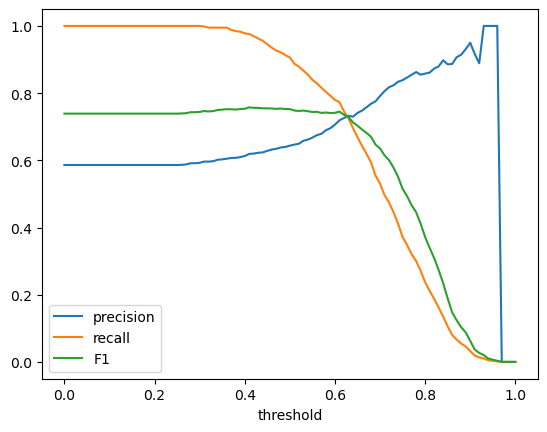

In [28]:
# Calculate the numbers to get the confusion table
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []
f1_scores = [] # question 4

for t in thresholds:
    # Check if the predicted value above the threshold
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    # Calculate the different parts of the confusion matrix
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    # Avoid division by zero
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0 # question 4

    precisions.append(p)
    recalls.append(r)
    f1_scores.append(f1)

# Visualize the calculated numbers
plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.plot(thresholds, f1_scores, label='F1') # question 4
plt.xlabel('threshold')
plt.legend()
plt.show()

In [29]:
# Difference between precision and recall per threshold
diff = np.abs(np.array(precisions) - np.array(recalls))

# Ignore thresholds where nothing is predicted positive
diff[np.array(precisions) == 0] = np.inf

# Threshold with the smallest difference = intersection
print(f'{thresholds[diff.argmin()]:.2f}')

0.63


##### Question 4

In [30]:
# See the graph above > threshold where F1 is maximal
print(f'{thresholds[np.argmax(f1_scores)]:.2f}')

0.41


##### Question 5

In [ ]:
# Train on one part of the data, return y_val and predicted probabilities
def train_predict(df_train, df_val, target='converted', C=1.0):
    # Separate the target > df_full_train still has it, unlike df_train and df_val
    y_train = df_train[target].values
    y_val = df_val[target].values
    df_train = df_train.drop(columns=target)
    df_val = df_val.drop(columns=target)

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train.to_dict(orient='records'))
    X_val = dv.transform(df_val.to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return y_val, model.predict_proba(X_val)[:, 1]

# Split df_full_train into 5 random folds
kf = KFold(n_splits=5, shuffle=True, random_state=1)
aucs = []

# Each round: train on 4 folds, validate on 1
for train_idx, val_idx in tqdm(kf.split(df_full_train), total=5):
    y_va, y_proba = train_predict(df_full_train.iloc[train_idx],
                                  df_full_train.iloc[val_idx])
    # AUC on the validation fold
    aucs.append(my_auc(y_va, y_proba))

print(f'mean: {np.mean(aucs):.3f}, std: {np.std(aucs):.3f}')

  0%|          | 0/5 [00:00<?, ?it/s]

mean: 0.732, std: 0.007


##### Question 6

In [ ]:
# Use different values for regularization
reg = [0.000001, 0.001, 1]

kf = KFold(n_splits=5, shuffle=True, random_state=1)

for c in reg:
    aucs = [] # start fresh for every C
    # Each round: train on 4 folds, validate on 1
    for train_idx, val_idx in tqdm(kf.split(df_full_train), total=5):
        y_va, y_proba = train_predict(df_full_train.iloc[train_idx],
                                    df_full_train.iloc[val_idx],
                                    C=c) # regularization strength for this round
        # AUC on the validation fold
        aucs.append(my_auc(y_va, y_proba))

    print(f'reg: {c}, mean: {np.mean(aucs):.3f}, std: {np.std(aucs):.3f}')

  0%|          | 0/5 [00:00<?, ?it/s]

reg: 1e-06, mean: 0.617, std: 0.019


  0%|          | 0/5 [00:00<?, ?it/s]

reg: 0.001, mean: 0.749, std: 0.010


  0%|          | 0/5 [00:00<?, ?it/s]

reg: 1, mean: 0.732, std: 0.007
